In [2]:
%pip install openai

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install python-dotenv
#!pip install python-dotenv

from openai import OpenAI
from pydantic import BaseModel
from dotenv import load_dotenv
import os

load_dotenv()

# Initialize client
client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))

response = client.responses.create(
    model="gpt-4o",
    input="What is machine learning?"
    )
print(response.output_text)

Note: you may need to restart the kernel to use updated packages.
Machine learning is a branch of artificial intelligence (AI) that focuses on the development of algorithms and models allowing computers to learn from and make predictions or decisions based on data. Rather than being explicitly programmed for specific tasks, these systems improve their performance automatically through experience.

Here’s how it broadly works:

1. **Data Input**: Large volumes of data are used to train machine learning models. This data can be text, images, audio, or other types of information.

2. **Algorithms**: Different algorithms are used depending on the type of task. Common algorithms include linear regression, decision trees, neural networks, and support vector machines.

3. **Model Training**: The model is trained using the input data, adjusting its parameters to improve accuracy and performance.

4. **Prediction and Decision Making**: Once trained, the model can make predictions or decisions b

## Step 1: Setting Up OpenAI API Access

Install the OpenAI Python library and set up authentication using the API key provided by Ironhack.

Keep the API key out of notebook code and saved outputs.

In [4]:
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
print(".env found:", bool(env_path))

if env_path:
    load_dotenv(env_path)

print("API key loaded:", bool(os.getenv("OPENAI_API_KEY")))

.env found: True
API key loaded: True


In [5]:
%pip install --only-binary=:all: PyYAML

Note: you may need to restart the kernel to use updated packages.


In [6]:
pip install datasets

Note: you may need to restart the kernel to use updated packages.


## Step 2: Prepare Data Sets

### Step 2.1: Load Data Set directly into Python from Huggingface (without manually dowloading)
This step prepares product data. It tries to load the first 100 products from Hugging Face and puts them into a table called products_df. If that fails, it builds a table from the sample product written in the code.

In [7]:
# Install: pip install datasets
from datasets import load_dataset
import requests
from PIL import Image
import pandas as pd
from pathlib import Path
 
# Load dataset from HuggingFace
print("Loading product dataset...")
try:
    # Try loading the dataset
    dataset = load_dataset("ashraq/fashion-product-images-small", split="train[:100]")  # First 100 samples
    print(f"✓ Loaded {len(dataset)} products")
    
    # Convert to pandas for easier manipulation
    products_df = pd.DataFrame(dataset)
    print(f"Dataset columns: {products_df.columns.tolist()}")
    
except Exception as e:
    print(f"⚠ Could not load HuggingFace dataset: {e}")
    print("Using local images instead...")
    
    # Alternative: Use local images
    # Create a products.json file with product information
    products_data = [
        {
            "id": 1,
            "name": "Wireless Headphones",
            "price": 79.99,
            "category": "Electronics",
            "image_path": "images/product1.jpg"
        },
        # Add more products...
    ]
    
    products_df = pd.DataFrame(products_data)
 
# Create images directory
images_dir = Path("product_images")
images_dir.mkdir(exist_ok=True)
 
print(f"\n✓ Dataset prepared!")
print(f"  Total products: {len(products_df)}")

Loading product dataset...


✓ Loaded 100 products
Dataset columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image']

✓ Dataset prepared!
  Total products: 100


### Step 2.2 Check: Verify Product Details and Image

The dataset loaded 100 products. To check that the data is usable, I select the first product, print its name and category, and display its image.

Turtle Check Men Navy Blue Shirt
Apparel


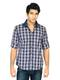

In [8]:
first_product = dataset[0]

print(first_product["productDisplayName"])
print(first_product["masterCategory"])
display(first_product["image"])

## Step 3 — Encode the first product photo for the API

Convert the first product photo from the dataset into JPEG bytes in memory, then encode those bytes as Base64 text. This prepares the photo for the API request in the next step.

To check the result, print the length of the Base64 text and preview its first 40 characters. The code also lists the table’s column names so we can see which product fields are available.

In [9]:
import base64
from io import BytesIO
from pathlib import Path
from PIL import Image

def encode_image_to_base64(image):
    buffer = BytesIO()
    image.convert("RGB").save(buffer, format="JPEG")
    return base64.b64encode(buffer.getvalue()).decode("utf-8")

sample_image = products_df.iloc[0]["image"]
encoded_image = encode_image_to_base64(sample_image)

print(f"Encoded image length: {len(encoded_image)} characters")
print(f"Encoded prefix: {encoded_image[:40]}...")

print(products_df.columns.tolist())

Encoded image length: 2388 characters
Encoded prefix: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcG...
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName', 'image']


## Step 4: Creating the Product Listing Prompt

Previously prepared the photo. Build a reusable prompt to send with the product photo in the next step. The prompt combines the product details with instructions to return a title, description, key features, and SEO keywords in JSON format.

Preview the prompt in the notebook to check that the product details and instructions appear as expected.


In [10]:
def create_product_listing_prompt(product_name, price, category, additional_info=None):
    """
    Create a prompt for generating product listings.
    
    Parameters:
    - product_name: Name of the product
    - price: Price of the product
    - category: Product category
    - additional_info: Optional additional information
    
    Returns:
    - Formatted prompt string
    """
    prompt = f"""You are an expert e-commerce copywriter. Analyze the product image and create a compelling product listing.
 
Product Information:
- Name: {product_name}
- Price: ${price:.2f}
- Category: {category}
{f'- Additional Info: {additional_info}' if additional_info else ''}
 
Please create a professional product listing that includes:
 
1. **Product Title** (catchy, SEO-friendly, 60 characters max)
2. **Product Description** (detailed, 150-200 words)
   - Highlight key features and benefits
   - Use persuasive language
   - Include relevant details visible in the image
3. **Key Features** (bullet points, 5-7 items)
4. **SEO Keywords** (comma-separated, 10-15 relevant keywords)
 
Format your response as JSON with the following structure:
{{
    "title": "Product title here",
    "description": "Full description here",
    "features": ["Feature 1", "Feature 2", ...],
    "keywords": "keyword1, keyword2, ..."
}}
 
Be specific about what you see in the image. Mention colors, materials, design elements, and any distinctive features."""
    
    return prompt
 
# Test prompt creation
test_prompt = create_product_listing_prompt(
    product_name="Wireless Bluetooth Headphones",
    price=79.99,
    category="Electronics",
    additional_info="Noise cancelling, 30-hour battery"
)
 
print("\n" + "="*50)
print("PROMPT TEMPLATE")
print("="*50)
print(test_prompt[:500] + "...")  # Show first 500 characters


PROMPT TEMPLATE
You are an expert e-commerce copywriter. Analyze the product image and create a compelling product listing.

Product Information:
- Name: Wireless Bluetooth Headphones
- Price: $79.99
- Category: Electronics
- Additional Info: Noise cancelling, 30-hour battery

Please create a professional product listing that includes:

1. **Product Title** (catchy, SEO-friendly, 60 characters max)
2. **Product Description** (detailed, 150-200 words)
   - Highlight key features and benefits
   - Use persuasive ...


## Step 5: Calling the OpenAI API with a Product Image

Create a listing prompt using the shirt’s name and category from the dataset. Send the prompt and the Base64-encoded shirt photo together in one API request. Read the response and parse it as JSON to access the title, description, key features, and SEO keywords.

Step 1 Prepare request. make sure variables already exist

In [27]:
image_data_url = f"data:image/jpeg;base64,{encoded_image}"

product_prompt = """
Analyze this product image and create a product listing.
Write a detailed product description of 150–200 words. Describe visible details such as color, pattern, shape, and design. Only mention materials or performance claims if they are provided in the product details.

Return only valid JSON with these fields:
{
  "title": "...",
  "description": "...",
  "category": "...",
  "features": ["...", "..."],
  "keywords": "keyword1, keyword2"
}
"""

request_input = [
    {
        "role": "user",
        "content": [
            {
                "type": "input_text",
                "text": product_prompt
            },
            {
                "type": "input_image",
                "image_url": image_data_url
            }
        ]
    }
]

print("Image data URL created:", image_data_url[:30] + "...")
print("Prompt created:", bool(product_prompt))
print("Request prepared:", bool(request_input))

Image data URL created: data:image/jpeg;base64,/9j/4AA...
Prompt created: True
Request prepared: True


### Step 5.2: Send the API Request

Send the prepared prompt and product image to the model, then print the response.

In [28]:
listing_response = client.responses.create(
    model="gpt-4o",
    input=request_input
)



In [29]:
print(listing_response.output_text) # 5.2 handle the response

```json
{
  "title": "Men's Casual Checkered Shirt",
  "description": "Upgrade your wardrobe with this stylish men's casual shirt, featuring a distinctive checkered pattern in a harmonious blend of blue and white. The shirt's design includes a sleek spread collar that adds a modern touch, with full-length sleeves that can be rolled up for a more relaxed look. The shirt is tailored to fit comfortably and is perfect for both casual outings and smart-casual events. The intricate check pattern offers a timeless appeal, making it an essential piece for any fashion-conscious individual. Pair it with jeans or chinos for an effortlessly chic ensemble.",
  "category": "Men's Clothing",
  "features": ["Checkered pattern", "Spread collar", "Full-length sleeves"],
  "keywords": "men's shirt, checkered shirt, casual shirt, blue shirt, spread collar"
}
```


### Step 5.4: Parse and Verify the Response

Converts the model’s reply from JSON text into a Python dictionary. Print the title and features to check that I can access individual fields.

In [30]:
import json

raw_text = listing_response.output_text.strip()
clean_text = raw_text.removeprefix("```json").removesuffix("```").strip()

listing = json.loads(clean_text)

print("Title:", listing["title"])
print("Features:", listing["features"])

Title: Men's Casual Checkered Shirt
Features: ['Checkered pattern', 'Spread collar', 'Full-length sleeves']


In [31]:
print(repr(listing_response.output_text))

'```json\n{\n  "title": "Men\'s Casual Checkered Shirt",\n  "description": "Upgrade your wardrobe with this stylish men\'s casual shirt, featuring a distinctive checkered pattern in a harmonious blend of blue and white. The shirt\'s design includes a sleek spread collar that adds a modern touch, with full-length sleeves that can be rolled up for a more relaxed look. The shirt is tailored to fit comfortably and is perfect for both casual outings and smart-casual events. The intricate check pattern offers a timeless appeal, making it an essential piece for any fashion-conscious individual. Pair it with jeans or chinos for an effortlessly chic ensemble.",\n  "category": "Men\'s Clothing",\n  "features": ["Checkered pattern", "Spread collar", "Full-length sleeves"],\n  "keywords": "men\'s shirt, checkered shirt, casual shirt, blue shirt, spread collar"\n}\n```'


## Step 6: Processing Multiple Products

Select three products from the dataset. Generate a listing for each product and save the results.

In [32]:
selected_products = dataset.select([0, 1, 2])

for product in selected_products:
    print(product["productDisplayName"])

Turtle Check Men Navy Blue Shirt
Peter England Men Party Blue Jeans
Titan Women Silver Watch


6.2 Generate a listing for each product

For each selected product, encode its photo, send it with the listing prompt, and parse the API reply as JSON. Collect the three listings in a Python list.

In [33]:
listings = []

for product in selected_products:
    print("Generating listing for:", product["productDisplayName"])

    encoded_product_image = encode_image_to_base64(product["image"])
    image_data_url = f"data:image/jpeg;base64,{encoded_product_image}"
    request_input = [
        {
            "role": "user",
            "content": [
                {"type": "input_text", "text": product_prompt},
                {"type": "input_image", "image_url": image_data_url}
            ]
        }
    ]

    response = client.responses.create(model="gpt-4o", input=request_input)

    raw_text = response.output_text.strip()
    clean_text = raw_text.removeprefix("```json").removesuffix("```").strip()
    listing = json.loads(clean_text)

    listings.append(listing)
    print("Generated title:", listing["title"])

print("Total listings generated:", len(listings))

Generating listing for: Turtle Check Men Navy Blue Shirt
Generated title: Men's Classic Blue Checkered Shirt
Generating listing for: Peter England Men Party Blue Jeans
Generated title: Men's Casual Straight Fit Jeans in Classic Blue
Generating listing for: Titan Women Silver Watch
Generated title: Elegant Silver Women's Wristwatch
Total listings generated: 3


## To review 
if the description provides a detailed description and catchy title as required in the lab

In [34]:
for listing in listings:
    description = listing["description"]
    print(listing["title"])
    print(description)
    print("Word count:", len(description.split()))
    print()

Men's Classic Blue Checkered Shirt
Upgrade your wardrobe with this Men's Classic Blue Checkered Shirt, perfect for both casual and semi-formal occasions. The shirt features a timeless checkered pattern in shades of blue and white, offering a clean and versatile look. Designed with a classic button-down front and a smart collar, it combines style with functionality. The short sleeves are ideal for warm weather, providing comfort while maintaining a polished appearance. Its slim fit tailoring adds a modern touch to the traditional design, making it suitable for various body types. Perfect for pairing with jeans or chinos, this shirt is a reliable addition to any fashion-forward man's collection.
Word count: 103

Men's Casual Straight Fit Jeans in Classic Blue
These versatile men's jeans offer a timeless look with their classic blue wash. Designed in a straight fit, they provide comfort and durability for everyday wear. The jeans feature a subtle faded pattern on the thighs and knees, add

Step 6.3: Save the Generated Listings

Save the generated listings to a JSON file. Read the file back and print its location and the number of listings it contains.

In [23]:
output_path = Path("product_listings.json")

with output_path.open("w", encoding="utf-8") as file:
    json.dump(listings, file, indent=2, ensure_ascii=False)

with output_path.open("r", encoding="utf-8") as file:
    saved_listings = json.load(file)

print("File saved to:", output_path.resolve())
print("Listings in the saved file:", len(saved_listings))

File saved to: C:\Users\momin\OneDrive\Desktop\AIPT2026\my first repo computer\my-first-repo\product_listings.json
Listings in the saved file: 3


## Step 7: Handle Errors for Individual Products

If a product fails during image processing, the API call, or JSON parsing, print its name and the error. Continue processing the remaining products.

In [20]:
import json
from openai import OpenAIError

In [21]:
try:
    # code that might fail
    ...
except (OpenAIError, OSError, json.JSONDecodeError, KeyError) as error:
    print(f"Skipped {product['productDisplayName']}: {error}")